# Programming a causal attention head

Choose query, key and value matrices so each token reports the running mean.

Set query and key projections to zero. After a causal mask, every visible key receives the same finite logit, so softmax gives equal weight to the prefix. An identity value projection preserves the features being averaged.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import softmax

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

running means [3. 2. 4. 3. 3. 4.]
max error 4.440892098500626e-16


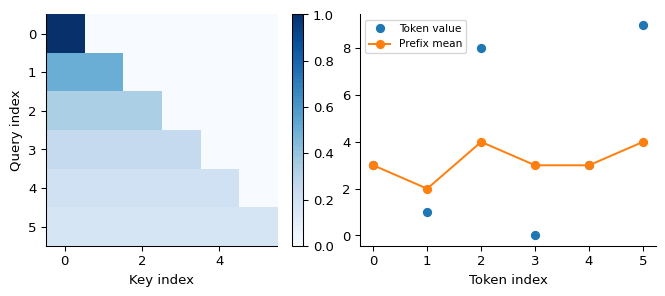

In [2]:
X = np.array([[3.0, 1.0], [1.0, 0.0], [8.0, 1.0], [0.0, 0.0], [3.0, 1.0], [9.0, 0.0]])
Q = K = np.zeros((2, 2))
V = np.eye(2)
logits = (X @ Q) @ (X @ K).T / np.sqrt(2)
logits[np.triu_indices(len(X), 1)] = -np.inf
attention = softmax(logits, axis=1)
output = attention @ (X @ V)
truth = X.cumsum(0) / np.arange(1, len(X) + 1)[:, None]
assert np.allclose(output, truth)
print("running means", output[:, 0].round(3))
print("max error", abs(output - truth).max())
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3), constrained_layout=True)
im = a.imshow(attention, cmap="Blues")
a.set(xlabel="Key index", ylabel="Query index")
fig.colorbar(im, ax=a)
b.plot(X[:, 0], "o", label="Token value")
b.plot(output[:, 0], "o-", label="Prefix mean")
b.set(xlabel="Token index")
b.legend(fontsize=8)
plt.show()

## Interpreting the result

Masking future positions is part of the computation. Zero logits alone would average the entire sequence. This head illustrates one operation found in program-to-transformer work.

## Exercise

Change the mask to include only the current and preceding two tokens.

## References

[Vaswani et al., Attention Is All You Need (2017)](https://arxiv.org/abs/1706.03762)

[Weiss, Goldberg and Yahav, Thinking Like Transformers (2021)](https://proceedings.mlr.press/v139/weiss21a.html)

[Lindner et al., Tracr (2023)](https://arxiv.org/abs/2301.05062)